# Results and Evaluation

In [32]:
# imports and paths 
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error, 
    accuracy_score, 
    f1_score, 
    roc_auc_score, 
    roc_curve, 
    confusion_matrix
)

ROOT = Path.cwd().resolve()
if not (ROOT / "presentation_material").exists():
    ROOT = ROOT.parent

# locate outputs
TASK1_DIR = ROOT / "presentation_material" / "task1" / "predictions"
TASK2_DIR = ROOT / "presentation_material" / "task2" / "predictions"

# Save figures and summary tables here.
RESULTS_DIR = ROOT / "presentation_material" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## Task 1 results
Comparison and evaluation of classical models (logistic regression, random forest) and the deep learning model (1D-CNN) against the mean baseline. 

In [14]:
# load predictions
task1_models = {
    "Majority baseline": "majority_baseline",
    "Logistic regression": "logistic_regression",
    "Random forest": "random_forest",
    "1D-CNN": "cnn_1d",
    "Logistic regression (tuned)": "logistic_regression_tuned",
    "Random forest (tuned)": "random_forest_tuned",
    "1D-CNN (tuned)": "cnn_1d_tuned",
}

task1_predictions = {}
for model_name, prefix in task1_models.items():
    paths = [TASK1_DIR / f"{prefix}_val_fold{k}.csv" for k in range(1, 6)]
    if all(p.exists() for p in paths):                      # skip models that have not been run
        task1_predictions[model_name] = pd.concat([pd.read_csv(p) for p in paths], ignore_index=True)
print(list(task1_predictions))

['Majority baseline', 'Logistic regression', 'Random forest', '1D-CNN', 'Logistic regression (tuned)', 'Random forest (tuned)', '1D-CNN (tuned)']


In [12]:
task1_results = []
for model_name, df in task1_predictions.items():
    fold_auc = [roc_auc_score(g.y_true, g.y_prob) for _, g in df.groupby("fold")]
    task1_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(df.y_true, df.y_pred),
        "F1": f1_score(df.y_true, df.y_pred),
        "ROC-AUC": roc_auc_score(df.y_true, df.y_prob),
        "AUC fold std": np.std(fold_auc, ddof=1),
    })

task1_summary = pd.DataFrame(task1_results).sort_index()
display(task1_summary.round(3))
task1_summary.round(4).to_csv(RESULTS_DIR / "task1_validation_summary.csv")


,Model,Accuracy,F1,ROC-AUC,AUC fold std
0,Majority baseline,0.561,0.718,0.484,0.000
1,Logistic regression,0.750,0.772,0.776,0.056
2,Random forest,0.727,0.753,0.736,0.075
3,1D-CNN,0.682,0.712,0.754,0.037
4,Logistic regression (tuned),0.750,0.772,0.776,0.056
5,Random forest (tuned),0.735,0.768,0.740,0.080
6,1D-CNN (tuned),0.682,0.720,0.758,0.048


All ML models proved to be better than the baseline since they all have a R0C-AUC > 0.484. Deep learning model did not give better results, best performing mode on task 1 is LogReg. Tuning the models also didn't significantly chance the ROC-AUC values. 

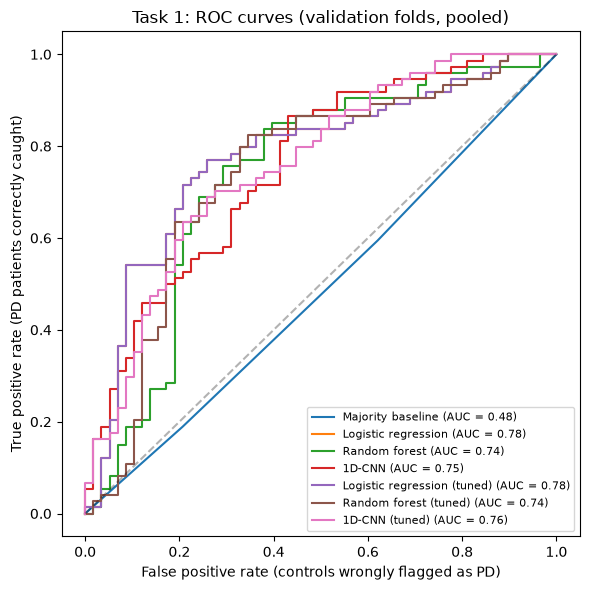

In [ ]:
# visual representation of results for task 1 (roc curves)
fig, ax = plt.subplots(figsize=(6, 6))
for model_name, df in task1_predictions.items():
    fpr, tpr, _ = roc_curve(df.y_true, df.y_prob)
    ax.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc_score(df.y_true, df.y_prob):.2f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.3)
ax.set_xlabel("False positive rate (controls wrongly flagged as PD)")
ax.set_ylabel("True positive rate (PD patients correctly caught)")
ax.set_title("Task 1: ROC curves (validation folds, pooled)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task1_roc_curves.png", dpi=150)
plt.show()

In [ ]:
# since logreg is the best model, elaborate on the metrics specific to it
log_reg = task1_predictions['Logistic regression']
cm = confusion_matrix(log_reg.y_true, log_reg.y_pred)
tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
tpr = tp / (tp+fn)
fpr = fp / (fp+tn)
print(round(tpr, 3))
print(round(fpr, 3))
# decent values, however 1/4 patients still missed

0.757
0.259


,Model,Accuracy change (%),F1 change (%),ROC-AUC change (%)
1,Logistic regression,33.8,7.5,60.2
4,Logistic regression (tuned),33.8,7.5,60.2
6,1D-CNN (tuned),21.6,0.2,56.6
3,1D-CNN,21.6,-0.9,55.8
5,Random forest (tuned),31.1,6.9,52.8
2,Random forest,29.7,4.9,52.0
0,Majority baseline,0.0,0.0,0.0


Not shown in chart (identical to default): ['Logistic regression (tuned)']


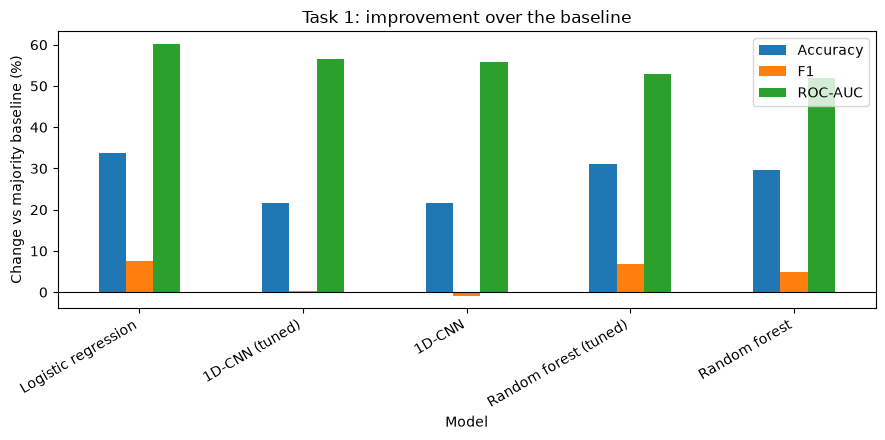

In [27]:
def compare_to_baseline(summary, baseline, metrics, higher_is_better=True):
    base = summary.loc[summary["Model"] == baseline, metrics].iloc[0]
    out = summary[["Model"]].copy()
    for m in metrics:
        diff = summary[m] - base[m]
        if not higher_is_better:
            diff = -diff                      # for error metrics, lower is better
        out[f"{m} change (%)"] = diff / base[m] * 100
    return out

metrics = ["Accuracy", "F1", "ROC-AUC"]
task1_vs_baseline = compare_to_baseline(task1_summary, "Majority baseline", metrics)
display(task1_vs_baseline.round(1))
task1_vs_baseline.round(2).to_csv(RESULTS_DIR / "task1_vs_baseline.csv", index=False)

# chart: skip tuned models that score the same as their default version
scores = task1_summary.set_index("Model")[metrics].astype(float)

def same_as_default(name):
    if not name.endswith(" (tuned)"):
        return False
    default = name.replace(" (tuned)", "")
    return default in scores.index and np.allclose(scores.loc[name], scores.loc[default], atol=1e-4)

omitted = [m for m in scores.index if same_as_default(m)]
keep = [m for m in task1_vs_baseline["Model"] if m != "Majority baseline" and m not in omitted]
if omitted:
    print("Not shown in chart (identical to default):", omitted)

plot_df = task1_vs_baseline.set_index("Model").loc[keep]
plot_df.columns = [c.replace(" change (%)", "") for c in plot_df.columns]
ax = plot_df.plot(kind="bar", figsize=(9, 4.5))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Change vs majority baseline (%)")
ax.set_title("Task 1: improvement over the baseline")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task1_vs_baseline.png", dpi=150)
plt.show()

## Task 2 results

Comparison and evaluation of the classical models (multiple linear regression, random forests) and the deep learning model (1D-CNN) against the mean baseline. 

In [28]:
# load predictions
task2_models = {
    "Mean baseline": "mean_baseline",
    "MLR": "linear_regression",
    "Random forest": "random_forest",
    "1D-CNN": "cnn"
}

task2_predictions = {}

for model_name, filename_prefix in task2_models.items():
    fold_tables = [
        pd.read_csv(TASK2_DIR / f"{filename_prefix}_val_fold{k}.csv") for k in range(1, 6)]

    task2_predictions[model_name] = pd.concat(fold_tables, ignore_index=True)

In [29]:
# overall MAE and RMSE 
task2_results = []
for model_name, df in task2_predictions.items():

    actual = df["actual_UPDRSM"]
    predicted = df["predicted_UPDRSM"]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    task2_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse 
    })

# compare to mean baseline
task2_summary = pd.DataFrame(task2_results).sort_values("RMSE")

baseline_mae = task2_summary.loc[
    task2_summary["Model"] == "Mean baseline", "MAE"].iloc[0]

# compare MAE with baseline through percentage improvement (or not)
task2_summary["MAE improvement (%)"] = (
    (baseline_mae - task2_summary["MAE"])
    / baseline_mae * 100)

display(task2_summary.round(3))

,Model,MAE,RMSE,MAE improvement (%)
0,Mean baseline,6.503,8.050,0.000
1,MLR,6.506,8.173,-0.047
2,Random forest,6.609,8.393,-1.638
3,1D-CNN,7.064,8.618,-8.625
